In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import tensorflow as tf
from tensorflow.keras import layers, Sequential


from src.datasets import create_datasets, class_names
from src.ViT_model_definitions import build_small_vit, build_hybrid_model

2026-10-09 11:11:25.071064: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-09 11:11:25.086259: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-09 11:11:25.090928: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    device = "/GPU:0"
    print(f"Using GPU: {gpus[0]}")
else:
    device = "/CPU:0"
    print("No GPU detected. Using CPU.")


Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


I0000 00:00:1791544286.187499   15584 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791544286.194841   15584 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791544286.197401   15584 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355


### 01. Hyperparameters and dataset setup

In [3]:
IMG_SIZE = 64
CHANNELS = 3 
BATCH_SIZE = 32
LR = 0.001
EPOCHS = 30  # Change as needed.


models_path = Path("models")

In [4]:
train_ds, val_ds, test_ds = create_datasets()

Found 4200 files belonging to 2 classes.


I0000 00:00:1791544286.423126   15584 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791544286.430249   15584 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791544286.432724   15584 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1791544286.569473   15584 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Found 900 files belonging to 2 classes.
Found 900 files belonging to 2 classes.


### 02. Create the ViT model

In [5]:
vit_model = build_small_vit(
    image_size=IMG_SIZE,
    patch_size=8,
    embed_dim=64,
    num_heads=4,
    mlp_dim=128,
    num_transformer_layers=2,
    dropout=0.1,
    num_classes=len(class_names)
)

vit_model.summary()

Model: "small_vit"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ patch_embedding                 │ (None, 64, 64)         │        12,352 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_position_embedding          │ (None, 64, 64)         │         4,096 │
│ (AddPositionEmbedding)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 64, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 64, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,522 (326.26 KB)

 Trainable params: 83,522 (326.26 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
vit_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### 03. Train the pure ViT model

In [ ]:
# Create the ModelCheckpoint callback
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(filepath=models_path / "ai_capstone_keras_pure_vit_model.keras",
                                monitor='val_loss',      # or 'val_accuracy'
                                mode='min',              # 'min' for loss, 'max' for accuracy
                                save_best_only=True,
                                verbose=1
                               )

In [7]:
history_vit = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    callbacks=[],
    epochs=EPOCHS
)

Epoch 1/30


I0000 00:00:1791544291.221495   15666 service.cc:146] XLA service 0x7500a8003230 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791544291.221529   15666 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce GTX 1650, Compute Capability 7.5


 13/132 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.5066 - loss: 1.0168

I0000 00:00:1791544297.757524   15666 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


132/132 ━━━━━━━━━━━━━━━━━━━━ 20s 78ms/step - accuracy: 0.6868 - loss: 0.6412 - val_accuracy: 0.8156 - val_loss: 0.3873
Epoch 2/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8816 - loss: 0.2932 - val_accuracy: 0.9344 - val_loss: 0.1722
Epoch 3/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9474 - loss: 0.1449 - val_accuracy: 0.9411 - val_loss: 0.1525
Epoch 4/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9476 - loss: 0.1228 - val_accuracy: 0.9511 - val_loss: 0.1284
Epoch 5/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9596 - loss: 0.1135 - val_accuracy: 0.9733 - val_loss: 0.0755
Epoch 6/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9586 - loss: 0.1060 - val_accuracy: 0.9633 - val_loss: 0.0901
Epoch 7/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9660 - loss: 0.1012 - val_accuracy: 0.9700 - val_loss: 0.0925
Epoch 8/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9657 - loss: 0.0930 - val_accuracy: 0.96

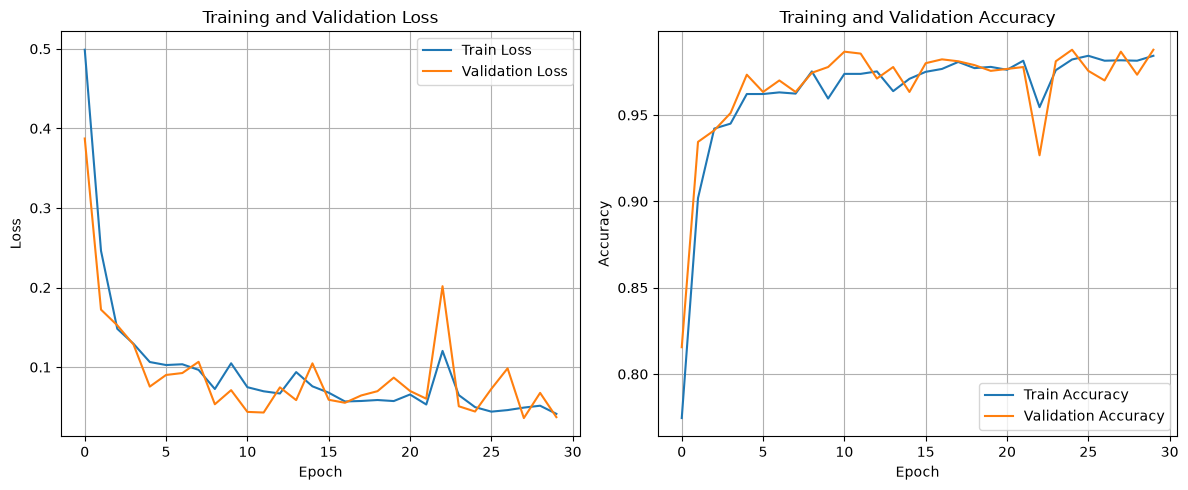

In [8]:
# Plot loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_vit.history["loss"], label="Train Loss")
plt.plot(history_vit.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

# Plot accuracy
plt.subplot(1, 2, 2)
plt.plot(history_vit.history["accuracy"], label="Train Accuracy")
plt.plot(history_vit.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 04. Create the hybrid model

In [9]:
pretrained_cnn_location = models_path / "ai_capstone_keras_best_small_model.keras"

hybrid_model = build_hybrid_model(pretrained_cnn_location)


hybrid_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


hybrid_model.summary()

Model: "cnn_vit_hybrid"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_24 (Functional)      │ (None, 4, 4, 128)      │        98,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 16, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_position_embedding_1        │ (None, 16, 128)        │         2,048 │
│ (AddPositionEmbedding)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_2             │ (None, 16, 128)        │       132,480 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 233,186 (910.88 KB)

 Trainable params: 134,786 (526.51 KB)

 Non-trainable params: 98,400 (384.38 KB)

### 05. Train the hybrid model

In [10]:

history_hybrid = hybrid_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 14s 61ms/step - accuracy: 0.9822 - loss: 0.0347 - val_accuracy: 0.9900 - val_loss: 0.0401
Epoch 2/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9975 - loss: 0.0073 - val_accuracy: 0.9944 - val_loss: 0.0209
Epoch 3/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9990 - loss: 0.0055 - val_accuracy: 0.9889 - val_loss: 0.0465
Epoch 4/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9990 - loss: 0.0049 - val_accuracy: 0.9933 - val_loss: 0.0230
Epoch 5/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9982 - loss: 0.0058 - val_accuracy: 0.9944 - val_loss: 0.0274
Epoch 6/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9977 - loss: 0.0067 - val_accuracy: 0.9911 - val_loss: 0.0451
Epoch 7/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9991 - loss: 0.0040 - val_accuracy: 0.9944 - val_loss: 0.0242
Epoch 8/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9992 - loss: 0.0032 - val_acc

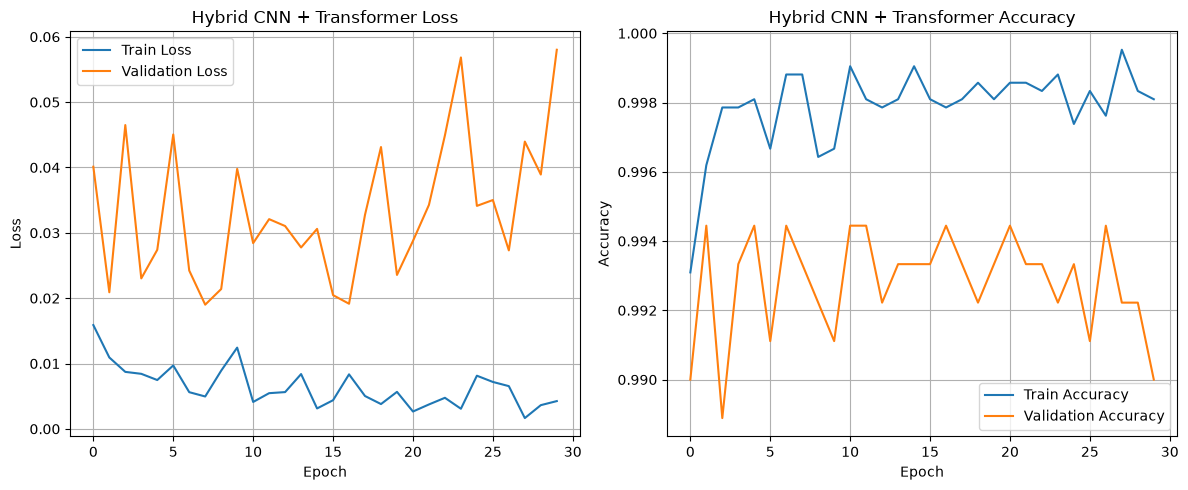

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_hybrid.history["loss"], label="Train Loss")
plt.plot(history_hybrid.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Hybrid CNN + Transformer Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_hybrid.history["accuracy"], label="Train Accuracy")
plt.plot(history_hybrid.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Hybrid CNN + Transformer Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [12]:
print(non_existant_variable)

NameError: name 'non_existant_variable' is not defined

In [14]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# ---------------------------------------------------------
# Load pretrained CNN
# ---------------------------------------------------------

cnn = tf.keras.models.load_model(
    pretrained_cnn_location
)

# Freeze pretrained CNN
cnn.trainable = False


# ---------------------------------------------------------
# Create input
# ---------------------------------------------------------

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, CHANNELS)
)


# ---------------------------------------------------------
# Feature extractor:
# keep only the first TWO CNN blocks
#
# Output:
# (batch, 16, 16, 32)
# ---------------------------------------------------------

feature_extractor = Model(
    inputs=cnn.layers[0].input,
    outputs=cnn.get_layer("max_pooling2d_5").output
)

feature_extractor.trainable = False

x = feature_extractor(inputs)


# ---------------------------------------------------------
# Convert feature map into tokens
#
# 16 × 16 = 256 tokens
# Each token has 32 features
#
# (batch, 16, 16, 32)
#       ↓
# (batch, 256, 32)
# ---------------------------------------------------------

x = layers.Reshape((256, 32))(x)


# ---------------------------------------------------------
# Positional embedding
# ---------------------------------------------------------

x = AddPositionEmbedding(
    num_patches=256,
    embed_dim=32
)(x)


# ---------------------------------------------------------
# Transformer block
# ---------------------------------------------------------

x = TransformerBlock(
    embed_dim=32,
    num_heads=4,
    mlp_dim=128,
    dropout=0.2
)(x)


# ---------------------------------------------------------
# Classification head
# ---------------------------------------------------------

x = layers.GlobalAveragePooling1D()(x)

x = layers.Dropout(0.1)(x)

outputs = layers.Dense(
    2,
    activation="softmax"
)(x)


# ---------------------------------------------------------
# Build model
# ---------------------------------------------------------

hybrid_half_CNN = Model(
    inputs=inputs,
    outputs=outputs,
    name="hybrid_half_CNN"
)


# ---------------------------------------------------------
# Check model
# ---------------------------------------------------------

hybrid_half_CNN.summary()

NameError: name 'AddPositionEmbedding' is not defined

In [ ]:
hybrid_half_CNN.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_half_CNN = hybrid_half_CNN.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(history_half_CNN.history["loss"], label="Train Loss")
plt.plot(history_half_CNN.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Half-CNN + Transformer Loss")
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(history_half_CNN.history["accuracy"], label="Train Accuracy")
plt.plot(history_half_CNN.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Half-CNN + Transformer Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Get class names

misclassified_images = []
misclassified_true = []
misclassified_pred = []
misclassified_conf = []

# Go through the entire validation set
for images, labels in val_ds:
    predictions = hybrid_half_CNN.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)
    confidences = np.max(predictions, axis=1)

    for i in range(len(images)):
        if predicted_classes[i] != labels[i].numpy():
            misclassified_images.append(images[i].numpy())
            misclassified_true.append(labels[i].numpy())
            misclassified_pred.append(predicted_classes[i])
            misclassified_conf.append(confidences[i])

print(f"Misclassified images: {len(misclassified_images)}")

In [ ]:
import math
import matplotlib.pyplot as plt

n = len(misclassified_images)

if n == 0:
    print("No misclassified images!")
else:
    cols = min(4, n)
    rows = math.ceil(n / cols)

    plt.figure(figsize=(12, 3 * rows))

    for i in range(n):
        ax = plt.subplot(rows, cols, i + 1)

        # Convert 0–255 float32 -> uint8
        image = np.clip(misclassified_images[i], 0, 255).astype(np.uint8)

        plt.imshow(image)

        plt.title(
            f"True: {class_names[misclassified_true[i]]}\n"
            f"Pred: {class_names[misclassified_pred[i]]}\n"
            f"Conf: {misclassified_conf[i]:.3f}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()